In [13]:
# Импорт библиотек
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (accuracy_score, classification_report, 
                           confusion_matrix, mean_squared_error, r2_score)
from sklearn.preprocessing import StandardScaler
import os
import pathlib
from sklearn.inspection import permutation_importance
import shap

# Установка стилей
plt.style.use('seaborn-v0_8')  # Исправленный стиль
sns.set_theme(style="whitegrid")  # Альтернативный способ установки стиля
%matplotlib inline

In [3]:
# Загрузка данных
DATA_PATH = 'wine+quality/'
TRAIN_PATH = DATA_PATH + 'winequality-red.csv'
TEST_PATH = DATA_PATH + 'winequality-white.csv'

# Проверка путей с обработкой ошибок
try:
    print("Проверка доступности файлов:")
    print("Красное вино:", os.path.exists(TRAIN_PATH))
    print("Белое вино:", os.path.exists(TEST_PATH))
    
    if not os.path.exists(TRAIN_PATH) or not os.path.exists(TEST_PATH):
        raise FileNotFoundError("Один или оба файла не найдены")
        
    # Загрузка данных
    red_wine = pd.read_csv(TRAIN_PATH, sep=';')
    white_wine = pd.read_csv(TEST_PATH, sep=';')

except FileNotFoundError as e:
    print(f"Ошибка: {e}")
    print("Пожалуйста, проверьте пути к файлам и их наличие")
    exit()
except Exception as e:
    print(f"Неожиданная ошибка: {e}")
    exit()

# Добавление меток типа вина
red_wine['wine_type'] = 'red'
white_wine['wine_type'] = 'white'

# Объединение датасетов
wines = pd.concat([red_wine, white_wine], ignore_index=True)

Проверка доступности файлов:
Красное вино: True
Белое вино: True


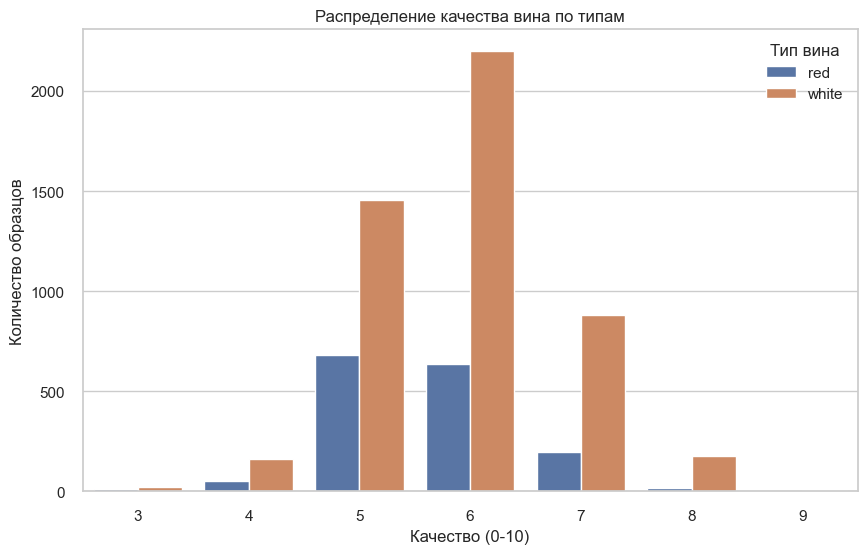

In [4]:
# Функция для визуализации
def plot_quality_distribution(data):
    plt.figure(figsize=(10, 6))
    sns.countplot(x='quality', hue='wine_type', data=data)
    plt.title('Распределение качества вина по типам')
    plt.xlabel('Качество (0-10)')
    plt.ylabel('Количество образцов')
    plt.legend(title='Тип вина')
    plt.show()

# Вызов функции
plot_quality_distribution(wines)

In [5]:
# Предварительный анализ данных
print("\nПервые 5 строк данных:")
display(wines.head())

print("\nИнформация о данных:")
print(wines.info())

print("\nОписательная статистика:")
display(wines.describe())


Первые 5 строк данных:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red



Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB
None

Описательная статистика:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


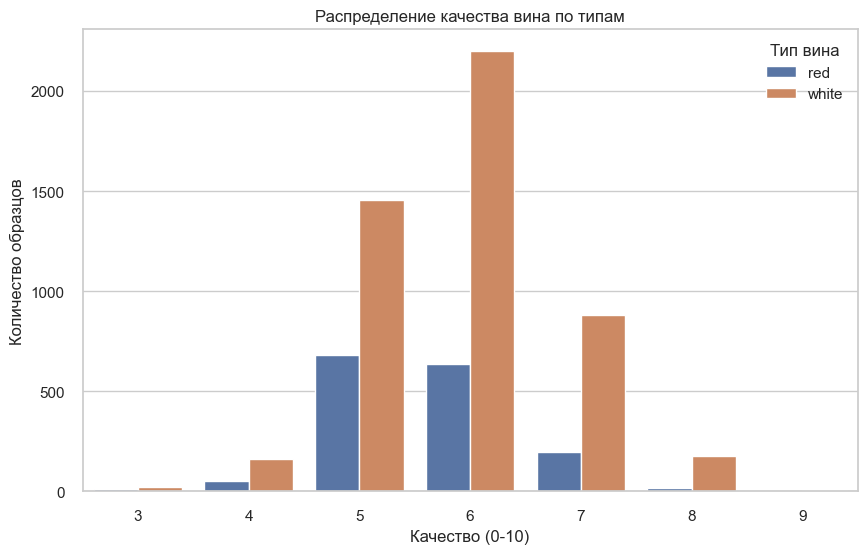

In [6]:
# Визуализация распределения качества
plt.figure(figsize=(10, 6))
sns.countplot(x='quality', hue='wine_type', data=wines)
plt.title('Распределение качества вина по типам')
plt.xlabel('Качество (0-10)')
plt.ylabel('Количество образцов')
plt.legend(title='Тип вина')
plt.show()

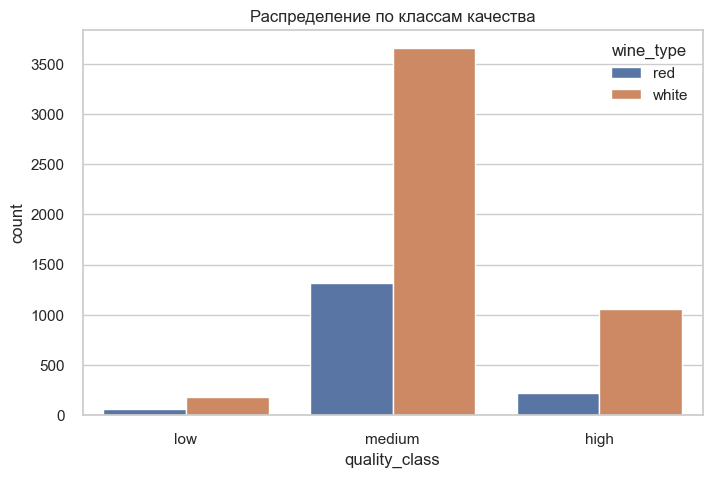

In [7]:
# Разделение на 3 класса качества
def classify_quality(quality):
    if quality <= 4:
        return 'low'
    elif 5 <= quality <= 6:
        return 'medium'
    else:
        return 'high'

wines['quality_class'] = wines['quality'].apply(classify_quality)

# Визуализация классов
plt.figure(figsize=(8, 5))
sns.countplot(x='quality_class', hue='wine_type', data=wines, 
             order=['low', 'medium', 'high'])
plt.title('Распределение по классам качества')
plt.show()

In [8]:
# Подготовка данных для классификации
X = wines.drop(['quality', 'quality_class', 'wine_type'], axis=1)
y_class = wines['quality_class']

# Разделение данных
X_train, X_test, y_train, y_test = train_test_split(
    X, y_class, test_size=0.3, random_state=42, stratify=y_class)

# Масштабирование признаков
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
# Обучение RandomForestClassifier
print("\nОбучение модели классификации...")
rf_clf = RandomForestClassifier(random_state=42, class_weight='balanced')

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}

grid_clf = GridSearchCV(rf_clf, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_clf.fit(X_train_scaled, y_train)

best_clf = grid_clf.best_estimator_
print(f"\nЛучшие параметры: {grid_clf.best_params_}")


Обучение модели классификации...

Лучшие параметры: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}



Анализ важности признаков:


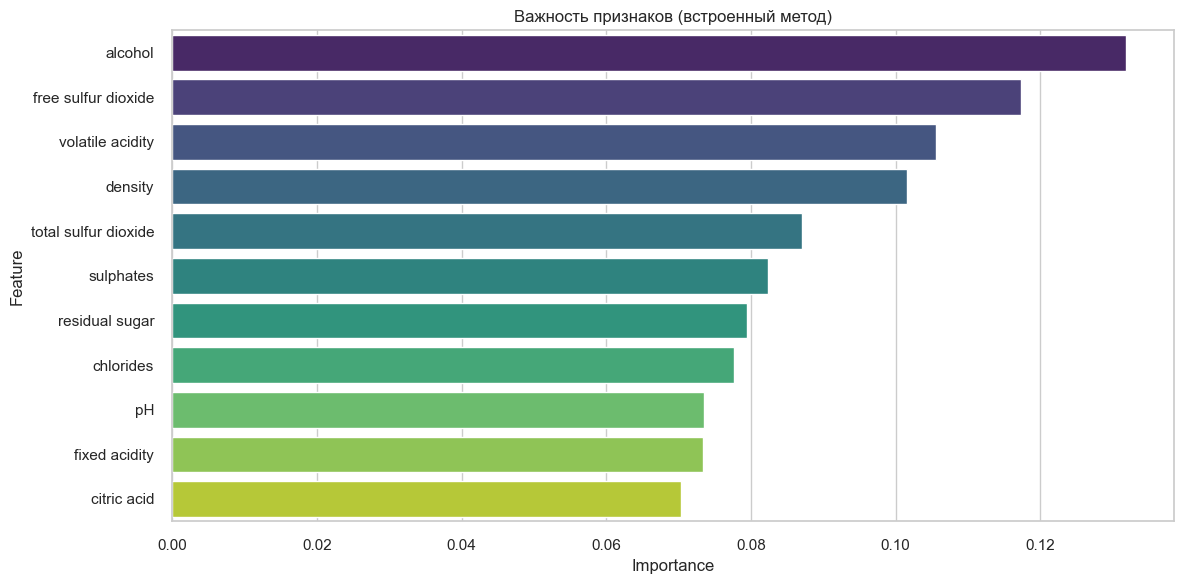

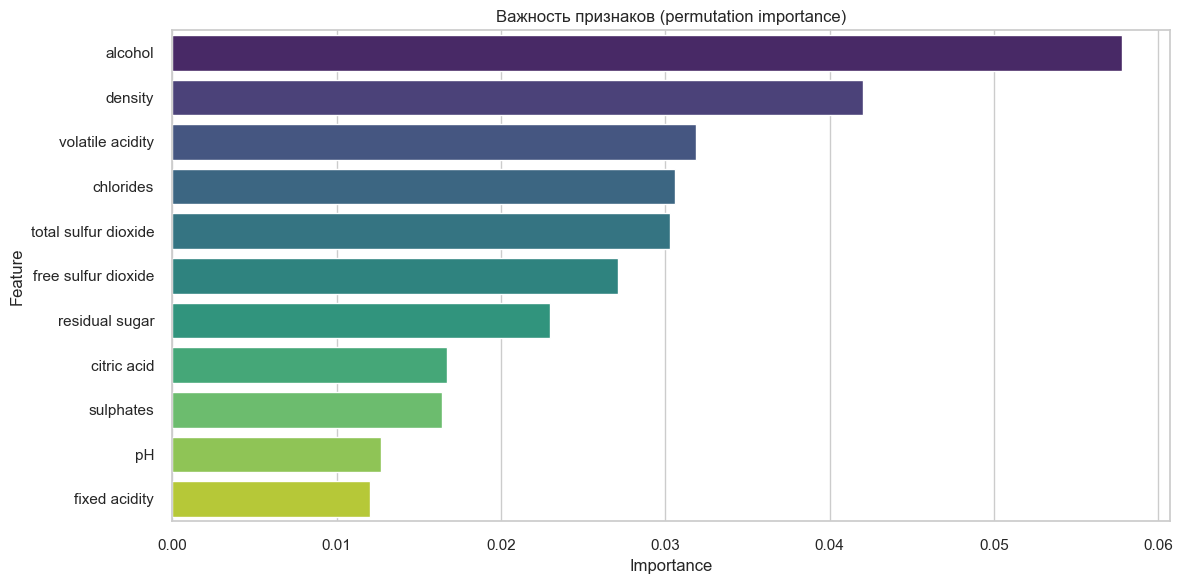

<Figure size 1200x600 with 0 Axes>

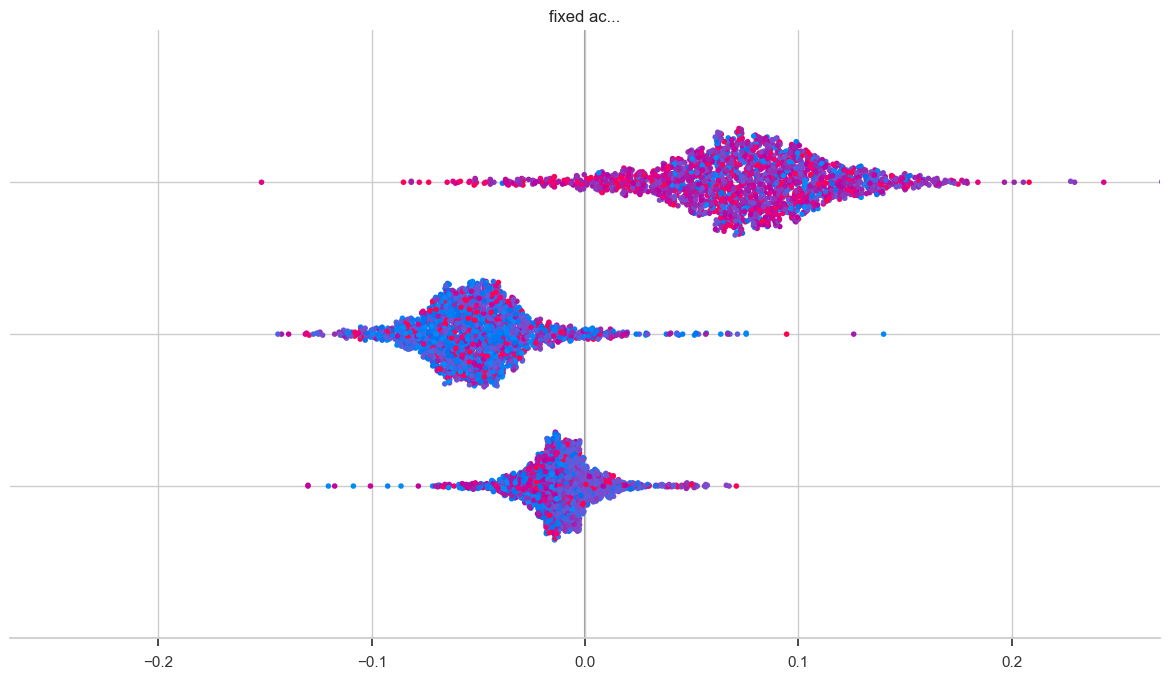

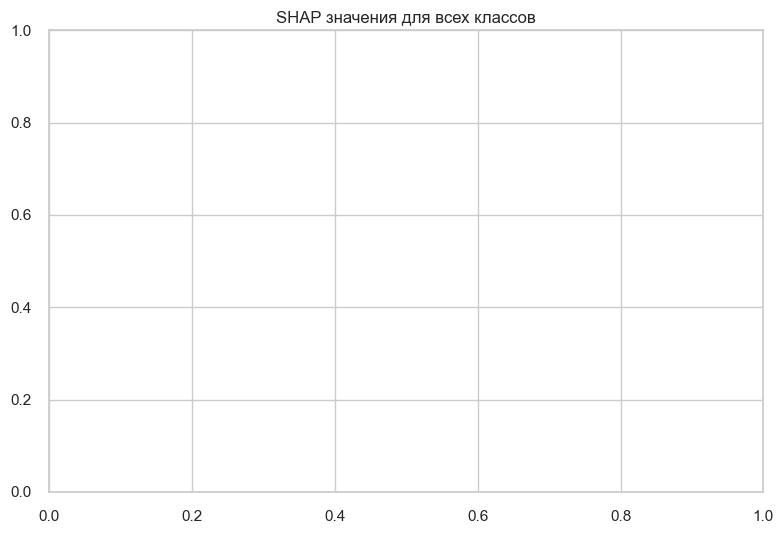

In [14]:
# Полный анализ важности признаков
print("\nАнализ важности признаков:")

# 1. Встроенная важность признаков
importances = best_clf.feature_importances_
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance, palette='viridis')
plt.title('Важность признаков (встроенный метод)')
plt.tight_layout()
plt.show()

# 2. Permutation Importance
result = permutation_importance(
    best_clf, X_test_scaled, y_test, n_repeats=10, random_state=42
)

perm_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': result.importances_mean
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x='Importance', y='Feature', data=perm_importance, palette='viridis')
plt.title('Важность признаков (permutation importance)')
plt.tight_layout()
plt.show()

# 3. SHAP значения
explainer = shap.TreeExplainer(best_clf)
shap_values = explainer.shap_values(X_test_scaled)

plt.figure(figsize=(12, 6))
shap.summary_plot(shap_values, X_test_scaled, feature_names=X.columns, class_names=best_clf.classes_)
plt.title('SHAP значения для всех классов')
plt.tight_layout()
plt.show()


Отчет о классификации:
              precision    recall  f1-score   support

        high       0.82      0.53      0.64       383
         low       1.00      0.07      0.13        74
      medium       0.85      0.97      0.91      1493

    accuracy                           0.85      1950
   macro avg       0.89      0.52      0.56      1950
weighted avg       0.85      0.85      0.83      1950



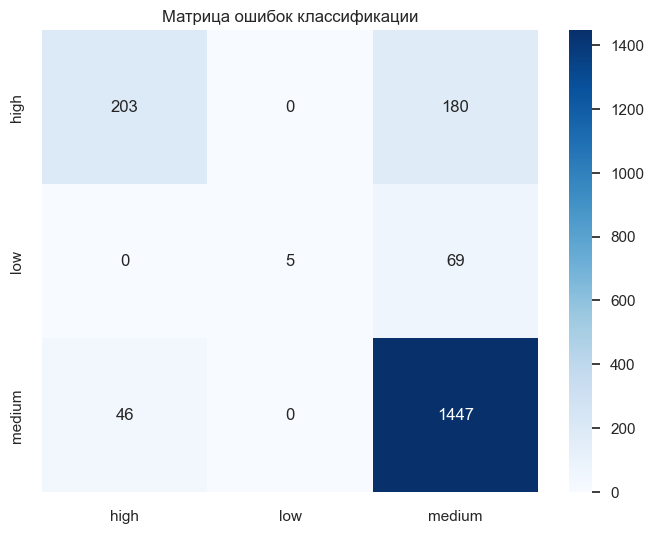

In [10]:
# Оценка модели классификации
y_pred = best_clf.predict(X_test_scaled)

print("\nОтчет о классификации:")
print(classification_report(y_test, y_pred))

# Матрица ошибок
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), 
            annot=True, fmt='d', cmap='Blues',
            xticklabels=best_clf.classes_,
            yticklabels=best_clf.classes_)
plt.title('Матрица ошибок классификации')
plt.show()